In [3]:
import sys

sys.path.insert(0, "../src")  # so we can import our own code from src/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config
from clean_snapshots import load_stations

df = pd.read_parquet(config.PROCESSED_DATA_DIR / "labeled_snapshots.parquet")
stations = load_stations()

# People live in New York time, so look at the data that way
df["local_time"] = df["time"].dt.tz_convert(config.TIMEZONE)
df["hour"] = df["local_time"].dt.hour
df["day"] = df["local_time"].dt.day_name()

print(f"{len(df):,} rows from {df['station_id'].nunique():,} stations")
print(f"{df['local_time'].min():%a %b %d %H:%M} to {df['local_time'].max():%a %b %d %H:%M}")
print(df["day"].value_counts())

1,374,355 rows from 2,466 stations
Wed Nov 18 18:25 to Fri Nov 20 18:50
day
Thursday     679536
Friday       531226
Wednesday    163593
Name: count, dtype: int64


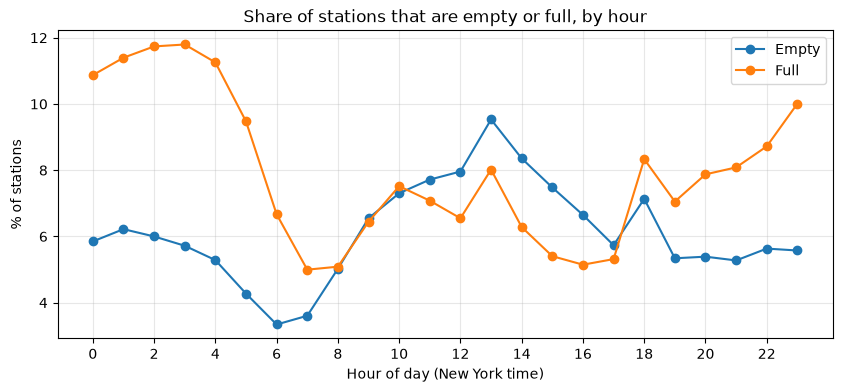

In [4]:
by_hour = df.groupby("hour")[["is_empty", "is_full"]].mean() * 100

ax = by_hour.plot(figsize=(10, 4), marker="o")
ax.set_title("Share of stations that are empty or full, by hour")
ax.set_xlabel("Hour of day (New York time)")
ax.set_ylabel("% of stations")
ax.set_xticks(range(0, 24, 2))
ax.legend(["Empty", "Full"])
ax.grid(alpha=0.3)
plt.show()

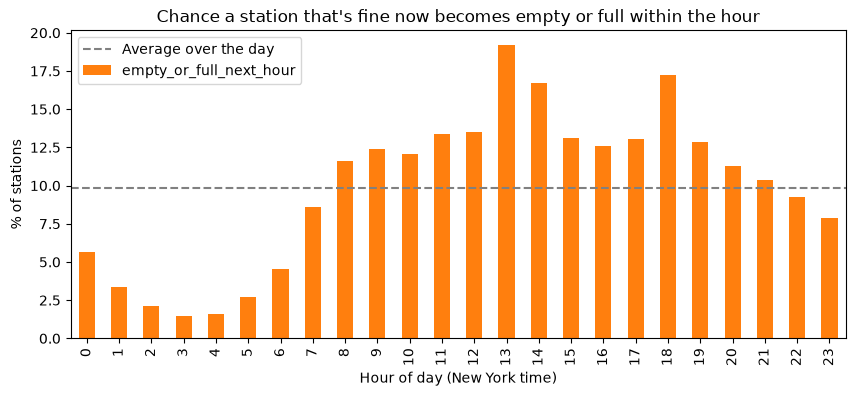

In [5]:
fine_now = df[df["is_empty_or_full"] == 0]
risk_by_hour = fine_now.groupby("hour")["empty_or_full_next_hour"].mean() * 100

ax = risk_by_hour.plot.bar(figsize=(10, 4), color="tab:orange")
ax.axhline(risk_by_hour.mean(), color="gray", linestyle="--", label="Average over the day")
ax.set_title("Chance a station that's fine now becomes empty or full within the hour")
ax.set_xlabel("Hour of day (New York time)")
ax.set_ylabel("% of stations")
ax.legend()
plt.show()

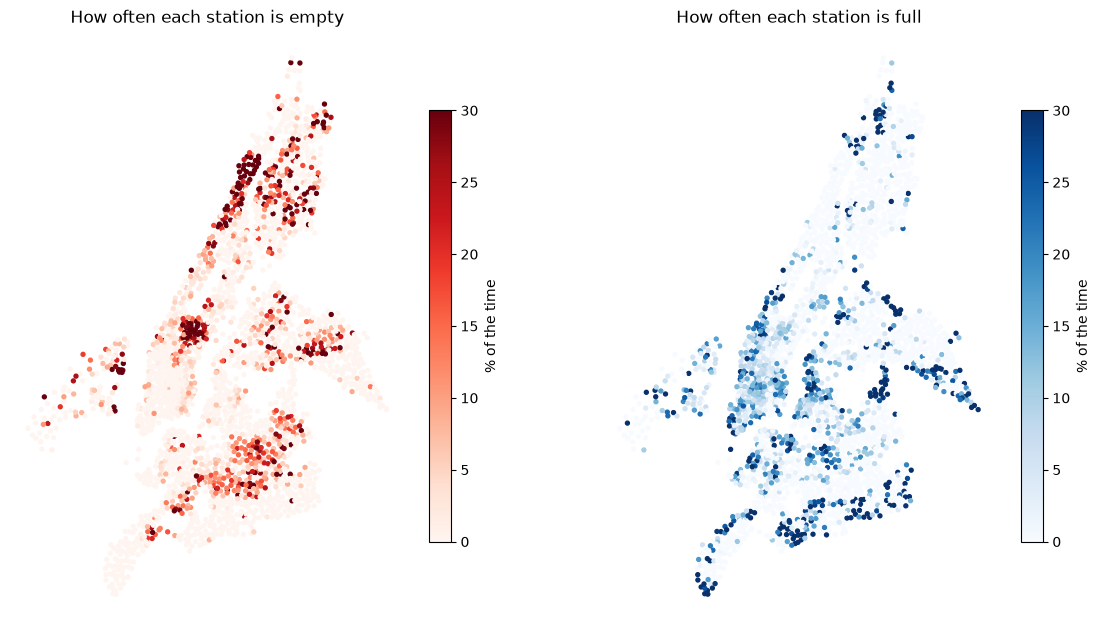

In [6]:
rates = df.groupby("station_id")[["is_empty", "is_full", "is_empty_or_full"]].mean() * 100
rates = rates.reset_index().merge(stations[["station_id", "name", "lat", "lon"]], on="station_id")

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, column, title, colors in [
    (axes[0], "is_empty", "How often each station is empty", "Reds"),
    (axes[1], "is_full", "How often each station is full", "Blues"),
]:
    points = ax.scatter(rates["lon"], rates["lat"], c=rates[column], cmap=colors, s=8, vmax=30)
    fig.colorbar(points, ax=ax, label="% of the time", shrink=0.7)
    ax.set_title(title)
    ax.set_aspect(1.32)  # so New York isn't stretched sideways
    ax.axis("off")
plt.show()

The worst 10% of stations (247) account for 38% of all empty or full moments


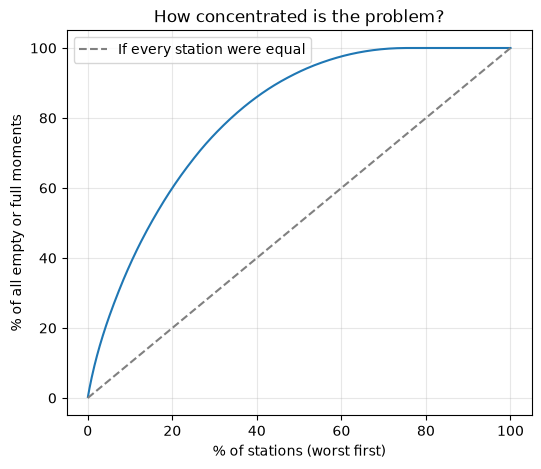

In [7]:
trouble = df.groupby("station_id")["is_empty_or_full"].sum().sort_values(ascending=False)
share = trouble.cumsum() / trouble.sum() * 100
stations_pct = np.arange(1, len(trouble) + 1) / len(trouble) * 100

worst_10_pct = round(len(trouble) * 0.10)
print(f"The worst 10% of stations ({worst_10_pct}) account for "
      f"{share.iloc[worst_10_pct - 1]:.0f}% of all empty or full moments")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(stations_pct, share)
ax.plot([0, 100], [0, 100], color="gray", linestyle="--", label="If every station were equal")
ax.set_xlabel("% of stations (worst first)")
ax.set_ylabel("% of all empty or full moments")
ax.set_title("How concentrated is the problem?")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [8]:
worst = rates.nlargest(10, "is_empty_or_full")[["name", "is_empty", "is_full", "is_empty_or_full"]]
worst.round(1)

,name,is_empty,is_full,is_empty_or_full
999,E 174 St & Longfellow Ave,100.0,100.0,100.0
1059,48 St & 2 Ave,0.0,100.0,100.0
2014,Gerard Ave & E 164 St,64.4,100.0,100.0
2436,Prospect Ave & Jennings St,0.0,100.0,100.0
2431,W 211 St & 10 Ave,26.0,95.9,95.9
2154,20 Ave & 48 St,0.0,93.3,93.3
762,Kings Hwy & E 98 St,0.0,93.1,93.1
376,W 233 St & Albany Crescent,0.0,93.1,93.1
395,Bailey Ave & W 229 St,0.0,90.4,90.4
1987,57 Rd & 59 St,0.0,88.4,88.4


In [9]:
suspects = ["E 174 St & Longfellow Ave", "48 St & 2 Ave", "Gerard Ave & E 164 St"]
columns = ["bikes_available", "docks_available", "bikes_disabled", "docks_disabled", "capacity"]

for station_id, name in stations.loc[stations["name"].isin(suspects), ["station_id", "name"]].itertuples(index=False):
    one = df[df["station_id"] == station_id]
    combos = one[columns].drop_duplicates()
    print(f"\n{name}: {len(one):,} snapshots, {len(combos)} different combinations of numbers")
    print(combos.head(5).to_string(index=False))


48 St & 2 Ave: 52 snapshots, 1 different combinations of numbers
 bikes_available  docks_available  bikes_disabled  docks_disabled  capacity
              16                0               3               0        19

Gerard Ave & E 164 St: 194 snapshots, 7 different combinations of numbers
 bikes_available  docks_available  bikes_disabled  docks_disabled  capacity
               0                0              18               0        19
               3                0              15               0        19
               2                0              16               0        19
               0                0              17               0        19
               1                0              17               0        19

E 174 St & Longfellow Ave: 581 snapshots, 2 different combinations of numbers
 bikes_available  docks_available  bikes_disabled  docks_disabled  capacity
               0                0              19               1        20
               0    

In [10]:
changes = df.groupby("station_id")[["bikes_available", "docks_available"]].nunique()
frozen_ids = changes[(changes["bikes_available"] == 1) & (changes["docks_available"] == 1)].index
print(f"{len(frozen_ids)} stations never changed their numbers at all")

no_space = df[(df["bikes_available"] + df["docks_available"]) == 0]
print(f"{no_space['station_id'].nunique()} stations had 0 bikes and 0 free docks at the same time")

frozen = stations[stations["station_id"].isin(frozen_ids)]
frozen["name"].head(20)

3 stations never changed their numbers at all
19 stations had 0 bikes and 0 free docks at the same time


20049         Ferris Triangle Park
18165                48 St & 2 Ave
18822    E 174 St & Longfellow Ave
Name: name, dtype: str